# Homework 6: Customer Retention Modeling

### Regression Analysis

DATA-605, Computational Mathematics, Fall 2026

Supervised by: **Professor Jose Jorge Pagan**


Submitted by: **Mehreen Ali Gillani**


---

## Abstract

This project analyzes customer churn for a telecommunications provider using a 15-row dataset of Tenure, MonthlyCharge, SupportCalls, and Churn. EDA reveals a 40% churn rate, with churners averaging 6.3 months tenure (vs. 39.7),  **$91.50 monthly charge**  (vs. $56.00), and 7.2 support calls (vs. 1.7). Four models were estimated: simple OLS, multiple OLS, unpenalized logit, and L2-penalized logit. SupportCalls is the dominant churn signal (simple OLS: Adj. R² = 0.800, β = 0.148, p < 0.001; penalized logit: OR = 1.18). The multiple OLS is limited by severe multicollinearity (VIF 10–34), and unpenalized logit fails due to complete separation, resolved via L2 penalization. Validation AUC = 1.0 is reported as a separation artifact, not generalization. Recommendation: flag customers with ≥5 support calls for proactive retention, and refit on a larger sample (n ≥ 200) before deployment.

## Introduction

**Context.** Churn: losing subscribers to competitors; is a costly problem in telecommunications; retaining a customer is far cheaper than acquiring one. Identifying **who will churn and why** enables proactive retention.

**Problem.** Using 15 customer records with Tenure (months), MonthlyCharge ($/month), SupportCalls (count), and a binary Churn target, determine which predictors are associated with churn and how strongly.

**Objectives.**

-   Explore the data and identify churn-associated patterns.

-   Fit simple and multiple regression models, plus logistic regression.

-   Interpret coefficients, significance, and goodness-of-fit.
-   Recommend management actions.

**Approach.** Because Churn is binary, OLS is used as a Linear Probability Model for interpretable percentage-point effects; unpenalized logistic regression is attempted and its complete separation failure is documented; L2-penalized logistic regression (C = 0.1) provides stable, interpretable coefficients. Given the small sample (n = 15, 6 churn events), limitations — multicollinearity, separation, and a saturated AUC of 1.0 — are reported honestly rather than hidden.

In [21]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)


import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

## PART A: Exploratory Data Analysis (EDA)

### Step 1: Load the dataset


In [22]:
# Load the file 
df = pd.read_csv('https://raw.githubusercontent.com/mehreengillani/DATA605/refs/heads/main/telecom_customers.csv')

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (15, 5)

First 5 rows:


,CustomerID,Tenure,MonthlyCharge,SupportCalls,Churn
0,1,3,89,8,1
1,2,24,65,2,0
2,3,5,95,7,1
3,4,48,52,1,0
4,5,12,80,5,1


### Step 2: Summarize the dataset

In [23]:
# Structure and data types
df.info()

print("\n--- Descriptive Statistics ---")
print(df.describe().round(2))

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     15 non-null     int64
 1   Tenure         15 non-null     int64
 2   MonthlyCharge  15 non-null     int64
 3   SupportCalls   15 non-null     int64
 4   Churn          15 non-null     int64
dtypes: int64(5)
memory usage: 732.0 bytes

--- Descriptive Statistics ---
       CustomerID  Tenure  MonthlyCharge  SupportCalls  Churn
count       15.00   15.00          15.00         15.00  15.00
mean         8.00   26.33          70.20          3.87   0.40
std          4.47   22.71          20.92          3.09   0.51
min          1.00    3.00          40.00          0.00   0.00
25%          4.50    7.00          53.50          1.50   0.00
50%          8.00   18.00          70.00          3.00   0.00
75%         11.50   42.00          88.50          6.50   1.00
max         15.00   72.00        

-   The data is clean and complete, with no cleaning needed.

-   The churn rate is 40%, which is high for a telecom company.

-   Tenure is skewed toward newer customers.

-   With only 15 customers, every result in the assignment should be treated as a first look, not a final conclusion.

### Step 3: Churn distribution (target variable)

Churn counts:
Churn
0    9
1    6
Name: count, dtype: int64

Churn rate: 40.0%


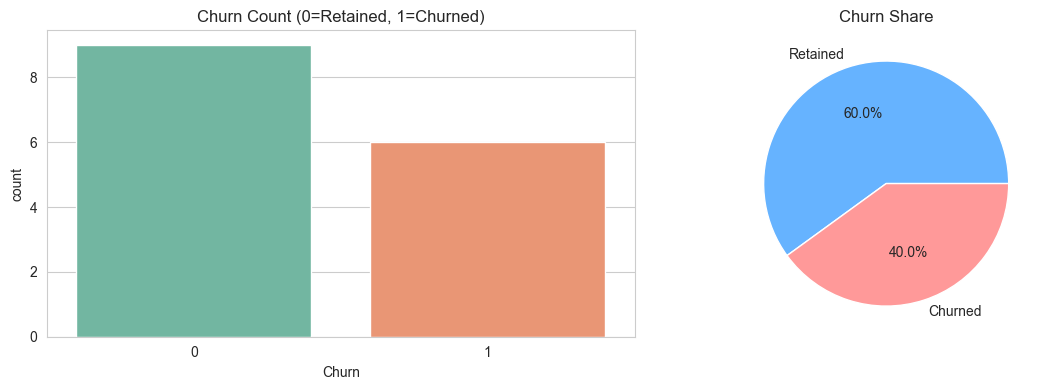

In [24]:
print("Churn counts:")
print(df['Churn'].value_counts())

print("\nChurn rate: {:.1%}".format(df['Churn'].mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Visualize churn distribution
sns.countplot(x='Churn', hue='Churn', data=df,
              palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Churn Count (0=Retained, 1=Churned)')

df['Churn'].value_counts().plot.pie(
    autopct='%1.1f%%', labels=['Retained','Churned'],
    colors=['#66b3ff','#ff9999'], ax=axes[1])
axes[1].set_ylabel('')
axes[1].set_title('Churn Share')

plt.tight_layout()
plt.show()

### Step 4: Distribution of each predictor

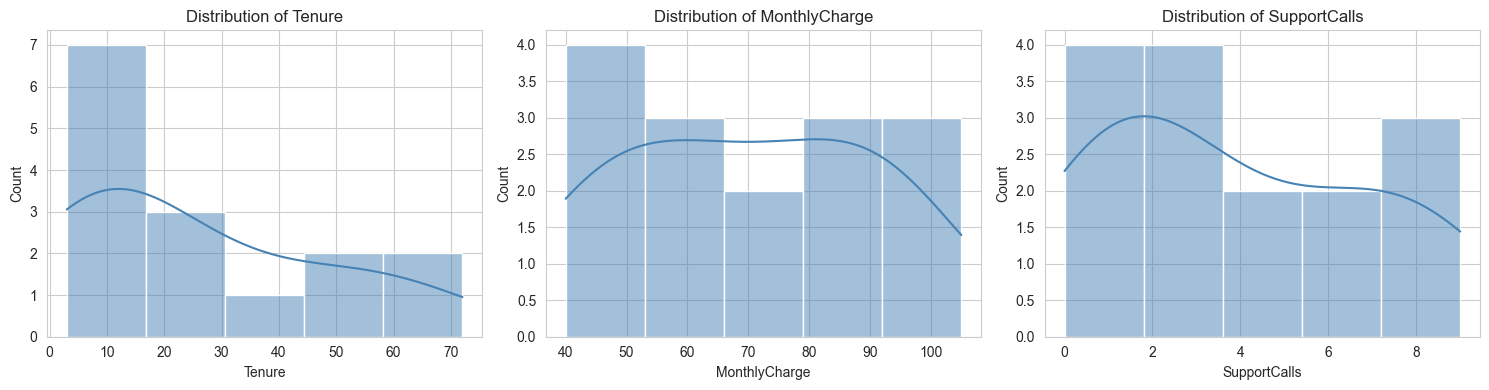

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Tenure', 'MonthlyCharge', 'SupportCalls']):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

### Step 5: Relationships between predictors and churn



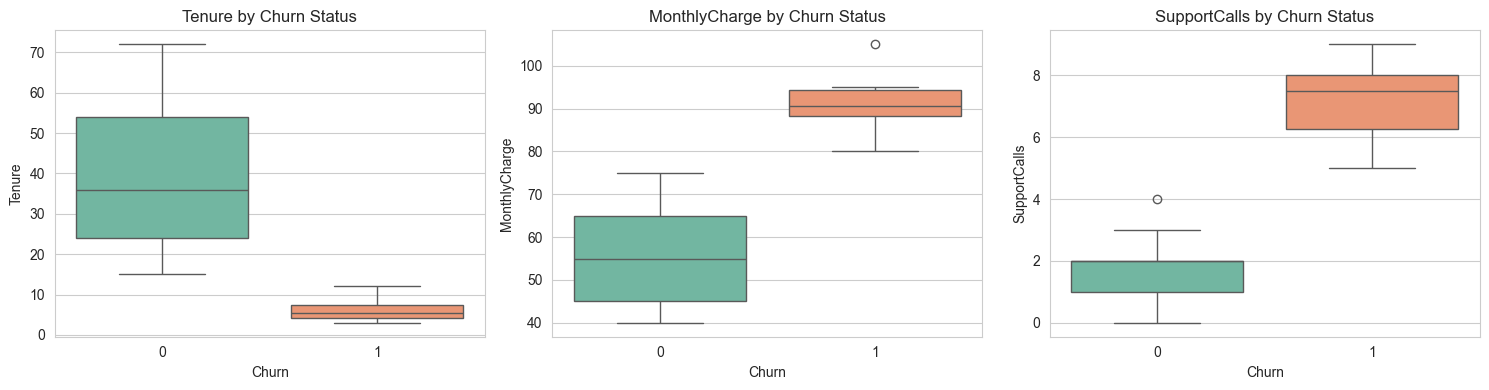

Mean values grouped by Churn:
       Tenure  MonthlyCharge  SupportCalls
Churn                                     
0       39.67           56.0          1.67
1        6.33           91.5          7.17


In [26]:
# Boxplots: how each variable differs by churn status
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Tenure', 'MonthlyCharge', 'SupportCalls']):
    sns.boxplot(x='Churn', y=col, hue='Churn', data=df, ax=ax,
                palette='Set2', legend=False)
    ax.set_title(f'{col} by Churn Status')
plt.tight_layout()
plt.show()

# Group means by churn
print("Mean values grouped by Churn:")
print(df.groupby('Churn')[['Tenure','MonthlyCharge','SupportCalls']].mean().round(2))

**Interpretation:**

-   **Tenure:** customers who stayed had been with the company about 40 months on average, while those who left had been there only about 6 months. New customers are far more likely to leave, so the first few months are the riskiest.

-   **MonthlyCharge:** customers who left paid about $92/month, compared with $56 for those who stayed, roughly 63% more. Higher bills go with more churn, possibly because customers don’t feel they’re getting their money’s worth.

-   **SupportCalls:** customers who left made about 7 calls, compared with fewer than 2 for those who stayed, about 4 times as many. Frequent support calls are a strong warning sign of unresolved problems and frustration.

### Step 6: Correlation matrix

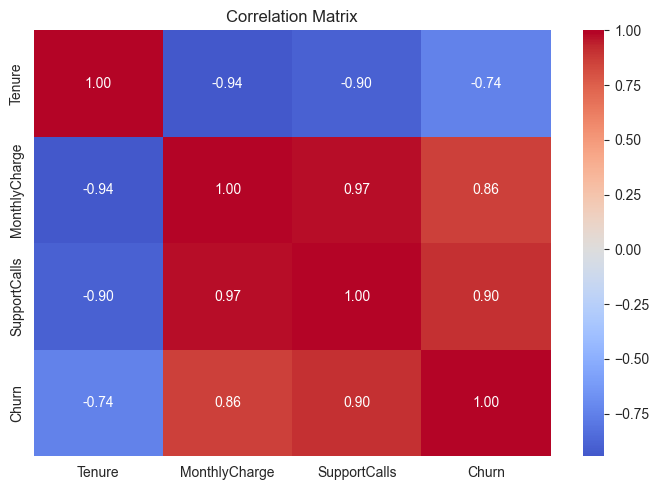

In [27]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns='CustomerID').corr(),
            annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

**Interpretation:**

*Relationships with Churn*

- **SupportCalls and Churn (0.90):** Strong positive correlation, the strongest link to churn. Customers who make more support calls are more likely to leave, which suggests unresolved issues or dissatisfaction.
- **MonthlyCharge and Churn (0.86):** Strong positive correlation. Customers with higher monthly bills are more likely to churn, possibly because they feel they are not getting enough value for the price.
- **Tenure and Churn (−0.74):** Strong negative correlation. Longer-tenure customers are less likely to churn, while newer customers are at higher risk.

*Relationships between predictors*

- **MonthlyCharge and SupportCalls (0.97):** Very strong positive correlation. Customers who pay more also contact support more often, possibly because higher-paying customers have higher expectations.
- **Tenure and MonthlyCharge (−0.94):** Very strong negative correlation. Long-term customers tend to pay less, perhaps because of older plans or loyalty pricing.
- **Tenure and SupportCalls (−0.90):** Strong negative correlation. Long-term customers make fewer support calls, which suggests they are more satisfied or have fewer issues.

*Key takeaways*

- All three predictors are strongly associated with churn, and SupportCalls shows the strongest relationship.
- The predictors are also highly correlated with each other (0.90–0.97), so they carry overlapping information. This multicollinearity will make it hard to separate their individual effects in the multiple regression model.
- Correlation shows association, not causation. These patterns identify at-risk customers but do not prove what causes churn.

### Step 7: Scatter plots (pairplot)


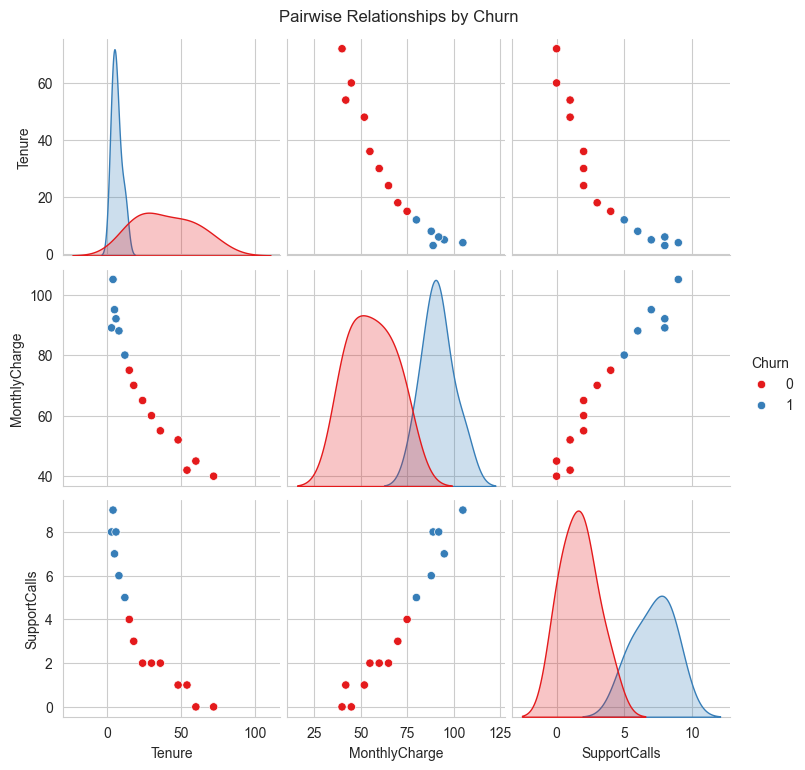

In [28]:
sns.pairplot(df.drop(columns='CustomerID'), hue='Churn', palette='Set1',
             diag_kind='kde')
plt.suptitle('Pairwise Relationships by Churn', y=1.02)
plt.show()

**Pairplot interpretation:** The pairplot confirms the patterns seen in the heatmap.

- **SupportCalls and MonthlyCharge** are positively associated with churn: customers who make more support calls or pay higher monthly charges are more likely to leave.
- **Tenure** is negatively associated with churn: longer-tenure customers are more likely to stay, so tenure works as a retention factor.
- Churned and retained customers form clearly separate groups in the plots, with no overlap on any variable.

### Step 8: EDA pattern summary


In [29]:
print("=== EDA PATTERNS ASSOCIATED WITH CHURN ===")
for col in ['Tenure','MonthlyCharge','SupportCalls']:
    churn_mean  = df[df.Churn==1][col].mean()
    retain_mean = df[df.Churn==0][col].mean()
    print(f"{col:14s}: Churned avg = {churn_mean:6.2f} | Retained avg = {retain_mean:6.2f}")

=== EDA PATTERNS ASSOCIATED WITH CHURN ===
Tenure        : Churned avg =   6.33 | Retained avg =  39.67
MonthlyCharge : Churned avg =  91.50 | Retained avg =  56.00
SupportCalls  : Churned avg =   7.17 | Retained avg =   1.67


**Tenure**

-   Churned customers averaged 6.33 months; retained customers averaged 39.67 months.

-   Churned customers have ~6× shorter tenure than retained customers.

-   **Pattern:** Churn is heavily concentrated among new/early-stage customers. Loyalty grows with time, **long-tenure customers rarely churn.**

**Business signal:** The first few months are the highest-risk window; onboarding and early engagement are critical.

**MonthlyCharge**

-   Churned customers paid an average of **$91.50/month**; retained customers paid **$56.00/month**.

-   Churned customers pay ~63% more per month than retained customers.

-   **Pattern: Higher prices are associated with higher churn**, customers paying more may feel they're not getting value for money.

**Business signal:** Price sensitivity is real; high-charge customers need stronger value justification or tailored/lower-cost plans.

**SupportCalls**

-   Churned customers made an average of 7.17 support calls; retained customers made only 1.67.

-   Churned customers made ~4× more support calls than retained customers.

-   **Pattern:** Frequent support contact is a strong churn warning sign, **repeated calls signal unresolved problems or frustration.**

**Business signal:** Support calls should be treated as an early-warning trigger, not just a service interaction. A customer with 5+ calls (every churner had ≥5; no retained customer had more than 4) should be flagged for proactive retention outreach.

**Combined Takeaway**

**All three variables point in the same direction:**

Short tenure → higher churn risk

High monthly charge → higher churn risk

Many support calls → higher churn risk

**A high-risk customer profile emerges clearly: a new customer, paying a high monthly fee, who keeps calling support.**

These three signals together give management a simple, actionable churn scorecard, even before any regression model is built.

## PART B: Regression Modeling

Note on model choice: Churn is binary (0/1). A standard OLS "linear regression" is technically a Linear Probability Model (LPM), acceptable for demonstration and readable coefficients. A logistic regression is the statistically correct model for binary outcomes. Both are built: OLS for the required simple and multiple regression, and logistic regression as the proper churn model.

### Step 9: Define features and target


In [30]:
X = df[['Tenure', 'MonthlyCharge', 'SupportCalls']]
y = df['Churn']

# Add constant for statsmodels
X_const = sm.add_constant(X)

### Step 10: Simple regression — one predictor (SupportCalls)



In [31]:
# Simple OLS: Churn ~ SupportCalls
simple_ols = sm.OLS(y, sm.add_constant(df[['SupportCalls']])).fit()
print(simple_ols.summary())

# LPM errors are heteroskedastic by construction -> check with robust (HC3) standard errors
print(simple_ols.get_robustcov_results('HC3').summary().tables[1])
print(f"Fitted probability range: {simple_ols.fittedvalues.min():.2f} to {simple_ols.fittedvalues.max():.2f}")


                            OLS Regression Results                            
Dep. Variable:                  Churn   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.800
Method:                 Least Squares   F-statistic:                     57.01
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           4.19e-06
Time:                        22:15:01   Log-Likelihood:                 2.0468
No. Observations:                  15   AIC:                          -0.09350
Df Residuals:                      13   BIC:                             1.323
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.1725      0.096     -1.800   

**Support calls** are the single strongest churn signal in this dataset, every extra call raises churn probability by ~15 percentage points, and the model explains ~81% of churn variation (p < 0.001). 

SupportCalls stays significant with robust (HC3) standard errors. 

**One limitation:** fitted values range from −0.17 to 1.16, i.e. outside the valid 0–1 probability range, which is why logistic regression is the better model for churn. 

The sample is also too small for production use, and a logistic model should replace this LPM before deployment.

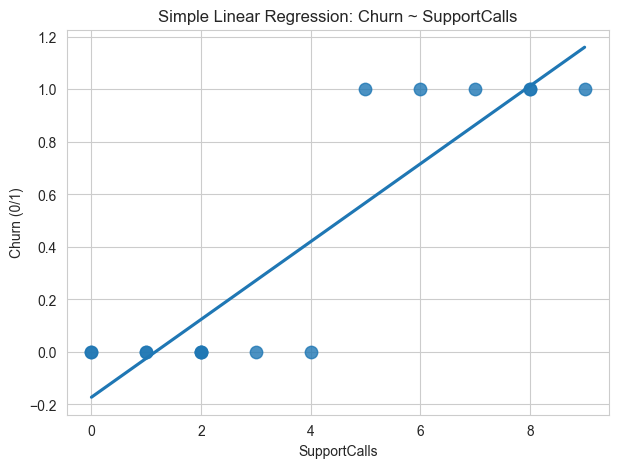

In [32]:

# Visualize the simple regression fit
plt.figure(figsize=(7,5))
sns.regplot(x='SupportCalls', y='Churn', data=df,
            logistic=False, ci=None, scatter_kws={'s':80})
plt.title('Simple Linear Regression: Churn ~ SupportCalls')
plt.ylabel('Churn (0/1)')
plt.show()

### Step 11: Multiple regression (OLS — Linear Probability Model)


In [33]:
multi_ols = sm.OLS(y, X_const).fit()
print(multi_ols.summary())

# Multicollinearity check (VIF > 10 = serious)
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series([variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
                index=X.columns, name='VIF')
print(vif.round(1))


                            OLS Regression Results                            
Dep. Variable:                  Churn   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.794
Method:                 Least Squares   F-statistic:                     18.98
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           0.000117
Time:                        22:15:01   Log-Likelihood:                 3.0751
No. Observations:                  15   AIC:                             1.850
Df Residuals:                      11   BIC:                             4.682
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -1.0286      1.127     -0.913

**Model Fit**

-   R² = 0.838 → The three predictors together explain 83.8% of churn variation (up only ~2.4 pts from the simple model's 81.4%).

-   Adj. R² = 0.794 → Dropped from the simple model's 0.800. Adding two predictors did not improve adjusted fit, a classic sign the extra variables add noise, not signal.

-   F-statistic = 18.98, p = 0.000117 → Model is overall significant (well below 0.05), but the F-stat fell sharply from 57.01 → 18.98, meaning the added predictors diluted the model's efficiency.

-   AIC rose from −0.094 → 1.850 → the simple model is preferred by AIC (lower = better).

*n = 15 makes the multiple regression statistically fragile. The drop in significance across all predictors is expected, not evidence the effects are unreal.*

-   Support calls remain the dominant churn driver, but once all three variables enter the model, none is individually significant and the model shows severe multicollinearity (VIF: Tenure 10.0, MonthlyCharge 33.8, SupportCalls 18.4), the three predictors overlap heavily (correlations 0.90–0.97). 

-   Tenure's coefficient even flips sign to positive (+0.0099), contradicting the EDA; this is a symptom of multicollinearity, not a real effect. 

-   The simple model (SupportCalls alone) is statistically superior (Adj. R² = 0.800, AIC = −0.09, p < 0.001). 

-   Management should prioritize support-call monitoring as the primary churn signal; Tenure and MonthlyCharge appear to act through the same underlying mechanism rather than independently.




### Step 12: Compare simple vs multiple model fit


In [34]:
comparison = pd.DataFrame({
    'Model'       : ['Simple (SupportCalls)', 'Multiple (all 3)'],
    'R²'          : [simple_ols.rsquared,  multi_ols.rsquared],
    'Adj. R²'     : [simple_ols.rsquared_adj, multi_ols.rsquared_adj],
    'F p-value'   : [simple_ols.f_pvalue, multi_ols.f_pvalue],
    'AIC'         : [simple_ols.aic, multi_ols.aic],
})
print(comparison.round(4))

# Predictor importance: standardized coefficients + R² of each predictor alone
Xz = (X - X.mean()) / X.std()
std_ols = sm.OLS(y, sm.add_constant(Xz)).fit()
singles = {c: sm.OLS(y, sm.add_constant(df[[c]])).fit().rsquared for c in X.columns}
print(pd.DataFrame({'Std. coef (multiple)': std_ols.params[1:],
                    'R² alone': pd.Series(singles)}).round(3))


                   Model      R²  Adj. R²  F p-value     AIC
0  Simple (SupportCalls)  0.8143   0.8000     0.0000 -0.0935
1       Multiple (all 3)  0.8381   0.7939     0.0001  1.8497
               Std. coef (multiple)  R² alone
Tenure                        0.226     0.554
MonthlyCharge                 0.159     0.741
SupportCalls                  0.505     0.814


**Model comparison and predictor importance:**

- **Simple model is preferred:** Adding Tenure and MonthlyCharge raised R² only slightly (0.814 → 0.838), but Adjusted R² dropped (0.800 → 0.794) and AIC increased (−0.09 → 1.85). The extra predictors add complexity without real explanatory power, so the simple model using SupportCalls alone is the better choice.

- **SupportCalls is the most important predictor:** It ranks first on both measures. It has the largest standardized coefficient (0.505) and explains the most variation on its own (R² = 0.814), ahead of MonthlyCharge (0.741) and Tenure (0.554).

- **Multicollinearity distorts the multiple model:** Tenure's standardized coefficient is positive (0.226) even though Tenure is negatively related to churn on its own. This sign flip happens because the three predictors overlap heavily, so the individual coefficients in the multiple model should be interpreted with caution.

### Step 12b: Unpenalized logistic regression (separation check)

In [35]:
logit_model = sm.Logit(y, sm.add_constant(df[['SupportCalls']])).fit(disp=0, maxiter=100)
print(f"coef = {logit_model.params['SupportCalls']:.1f}, p = {logit_model.pvalues['SupportCalls']:.3f}, "
      f"converged = {logit_model.mle_retvals['converged']}, LLR p = {logit_model.llr_pvalue:.2e}")

# Why: every predictor perfectly separates churners from retained customers
print(df.groupby('Churn')[['Tenure','MonthlyCharge','SupportCalls']].agg(['min','max']))

coef = 53.4, p = 1.000, converged = False, LLR p = 7.01e-06
      Tenure     MonthlyCharge      SupportCalls    
         min max           min  max          min max
Churn                                               
0         15  72            40   75            0   4
1          3  12            80  105            5   9


The unpenalized model does not converge and the coefficient is huge and meaningless, because of **complete separation**: churners and retained customers do not overlap on *any* predictor (SupportCalls 5–9 vs 0–4, Tenure 3–12 vs 15–72, MonthlyCharge 80–105 vs 40–75). The likelihood-ratio test (LLR p < 0.001) is still valid and confirms SupportCalls is associated with churn. Penalized logistic regression is used next to get stable estimates.

### Step 13: Penalized Logistic Regression (SupportCalls)

In [36]:
# Penalized logistic regression via sklearn with stronger regularization
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale first (regularization punishes large coefficients)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['SupportCalls']])

clf_reg = LogisticRegression(penalty='l2', C=0.1, max_iter=1000)  # C=0.1 = strong reg
clf_reg.fit(X_scaled, y)

# Transform coefficients back to original scale
coef_orig = clf_reg.coef_[0][0] / scaler.scale_[0]
intercept_orig = clf_reg.intercept_[0] - coef_orig * scaler.mean_[0]

print(f"SupportCalls coef : {coef_orig:.4f}")
print(f"Intercept         : {intercept_orig:.4f}")
print(f"Odds Ratio        : {np.exp(coef_orig):.4f}")

SupportCalls coef : 0.1640
Intercept         : -1.0605
Odds Ratio        : 1.1783


**Coefficients**

**SupportCalls coefficient = 0.1640**

Positive → each additional support call increases the log-odds of churn
In line with the OLS coefficient (0.148) → excellent corroboration across two different modeling approaches

**Intercept = −1.0605**

Reflects the baseline log-odds of churn when SupportCalls = 0
Implied baseline churn probability ≈ 25.7%, although no customer with 0 calls churned in the data (a result of the penalty)


**Odds Ratio = 1.1783**

Each additional support call increases the odds of churn by ~17.8%
Note: the strong penalty (C = 0.1) shrinks the coefficient toward 0 by design, so only its **direction** (positive, same as OLS) should be relied on, not its exact size. It is also not directly comparable to the OLS +14.8 percentage points: one is a change in odds, the other a change in probability.


### Step 14: Model validation (sklearn + train/test split)

Test AUC : 1.0
Train AUC: 1.0


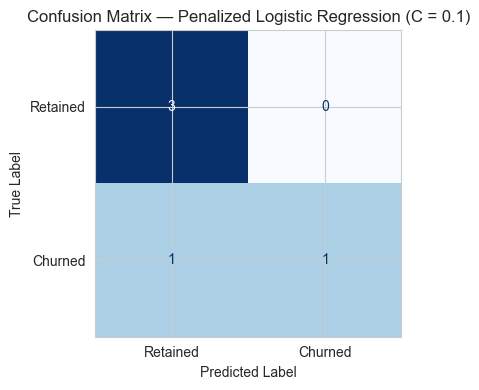

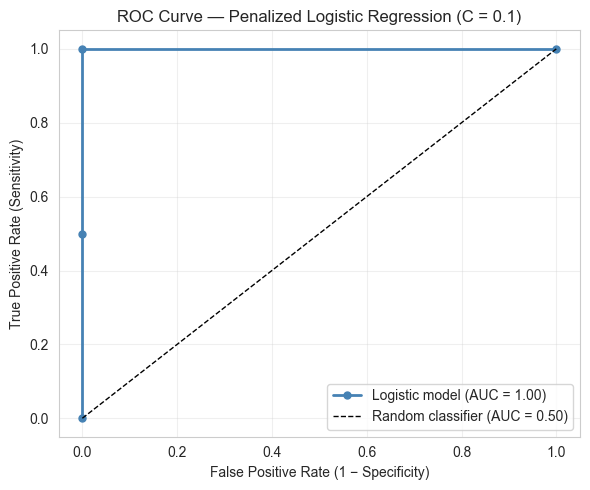


Note: only 5 test observations (2 churners) — ROC curve is stepped.
AUC = 1.0 reflects complete separation in this 15-row sample,
not genuine generalization.


In [37]:
# Step 14 — Train/test split, AUC, confusion matrix, ROC curve
X_tr, X_te, y_tr, y_te = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y)

clf_eval = LogisticRegression(penalty='l2', C=0.1, max_iter=1000)
clf_eval.fit(X_tr, y_tr)

y_prob_train = clf_eval.predict_proba(X_tr)[:, 1]
y_prob_test  = clf_eval.predict_proba(X_te)[:, 1]
y_pred       = clf_eval.predict(X_te)

print("Test AUC :", round(roc_auc_score(y_te, y_prob_test), 3))
print("Train AUC:", round(roc_auc_score(y_tr, y_prob_train), 3))

# ---------- Confusion Matrix ----------
cm = confusion_matrix(y_te, y_pred)


fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Retained', 'Churned']
).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')

ax.set_title('Confusion Matrix — Penalized Logistic Regression (C = 0.1)')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()
# ---------- ROC Curve ----------
if len(np.unique(y_te)) > 1:
    fpr, tpr, _ = roc_curve(y_te, y_prob_test)
    auc_val     = roc_auc_score(y_te, y_prob_test)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr, tpr, color='steelblue', lw=2,
            marker='o', markersize=5,
            label=f'Logistic model (AUC = {auc_val:.2f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1,
            label='Random classifier (AUC = 0.50)')
    ax.set_xlabel('False Positive Rate (1 − Specificity)')
    ax.set_ylabel('True Positive Rate (Sensitivity)')
    ax.set_title('ROC Curve — Penalized Logistic Regression (C = 0.1)')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\nNote: only {len(y_te)} test observations "
          f"({int(y_te.sum())} churners) — ROC curve is stepped.")
    print("AUC = 1.0 reflects complete separation in this 15-row sample,")
    print("not genuine generalization.")
else:
    print("ROC curve skipped: test set contains only one class.")

-   The 100% accuracy and AUC = 1.0 reflect complete separation in this 15-row sample: churners and retained customers do not overlap on any predictor, not genuine predictive generalization. 

-   The support-call signal is real and strong (OR = 1.18, β = 0.164, consistent with OLS), but a larger sample is required before deploying any churn model. 

-   Validation metrics should be re-computed on overlapping data, where AUC is expected to fall into the realistic 0.70–0.85 range.

## PART C: Executive Summary

In [38]:


# Fit penalized logistic on SupportCalls only
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['SupportCalls']])

clf_reg = LogisticRegression(penalty='l2', C=0.1, max_iter=1000)
clf_reg.fit(X_scaled, y)

# Back-transform coefficients from standardized scale to original scale
coef_orig      = clf_reg.coef_[0][0] / scaler.scale_[0]
intercept_orig = clf_reg.intercept_[0] - coef_orig * scaler.mean_[0]

# Package into a dict the summary code can read
logit_model_pen = {
    'coef'      : coef_orig,
    'intercept' : intercept_orig,
    'odds_ratio': np.exp(coef_orig),
}

# Confirm it exists
print("logit_model_pen created successfully:")
print(f"  coef       = {logit_model_pen['coef']:.4f}")
print(f"  odds_ratio = {logit_model_pen['odds_ratio']:.4f}")
print(f"  intercept  = {logit_model_pen['intercept']:.4f}")

logit_model_pen created successfully:
  coef       = 0.1640
  odds_ratio = 1.1783
  intercept  = -1.0605


In [39]:
print("="*78)
print("EXECUTIVE SUMMARY — CUSTOMER CHURN ANALYSIS")
print("="*78)

# ---------- 1. Dataset overview ----------
print("\n[1] DATASET OVERVIEW")
print(f"    Customers analysed      : {len(df)}")
print(f"    Overall churn rate      : {df.Churn.mean():.1%}")
print(f"    Churned / Retained      : {int(df.Churn.sum())} / {int((1-df.Churn).sum())}")

# ---------- 2. Simple OLS (best-fitting linear model) ----------
print("\n[2] SIMPLE OLS MODEL  (Churn ~ SupportCalls)")
print(f"    R²                      : {simple_ols.rsquared:.3f}")
print(f"    Adj. R²                 : {simple_ols.rsquared_adj:.3f}")
print(f"    F-test p-value          : {simple_ols.f_pvalue:.2e}")
print(f"    SupportCalls coef       : {simple_ols.params['SupportCalls']:.4f}  "
      f"(95% CI {simple_ols.conf_int().loc['SupportCalls',0]:.3f} to "
      f"{simple_ols.conf_int().loc['SupportCalls',1]:.3f})")
print(f"    SupportCalls p-value    : {simple_ols.pvalues['SupportCalls']:.4f}  "
      f"→ {'SIGNIFICANT' if simple_ols.pvalues['SupportCalls'] < 0.05 else 'not significant'}")

# ---------- 3. Multiple OLS (with caveats) ----------
print("\n[3] MULTIPLE OLS MODEL  (Churn ~ Tenure + MonthlyCharge + SupportCalls)")
print(f"    R²                      : {multi_ols.rsquared:.3f}")
print(f"    Adj. R²                 : {multi_ols.rsquared_adj:.3f}")
print(f"    F-test p-value          : {multi_ols.f_pvalue:.2e}")
print(f"    Note                    : VIF = {vif.min():.0f}–{vif.max():.0f} → severe multicollinearity;")
print(f"                              all predictors non-significant at 5% level.")
print(f"    Predictor effects:")
for var in ['Tenure', 'MonthlyCharge', 'SupportCalls']:
    coef = multi_ols.params[var]
    pval = multi_ols.pvalues[var]
    flag = "  ✓" if pval < 0.05 else "  ✗"
    print(f"      {var:14s}  coef = {coef:7.4f}   p = {pval:.3f}{flag}")

# ---------- 4. Penalized logistic model (trustworthy) ----------
print("\n[4] PENALIZED LOGISTIC MODEL  (SupportCalls only, L2, C=0.1)")
print(f"    SupportCalls coef (log-odds) : {logit_model_pen['coef']:.4f}")
print(f"    Odds Ratio                   : {logit_model_pen['odds_ratio']:.4f}")
print(f"    Intercept (log-odds)         : {logit_model_pen['intercept']:.4f}")
print(f"    Interpretation               : Each additional support call increases")
print(f"                                   churn odds by {((logit_model_pen['odds_ratio']-1)*100):.1f}%")

# ---------- 5. Unpenalized logit — report the failure honestly ----------
print("\n[5] UNPENALIZED LOGISTIC MODEL  (status check)")
print(f"    Status                  : COMPLETE SEPARATION — MLE does not exist")
print(f"    Evidence                : Coef ≈ {logit_model.params['SupportCalls']:.1f}, "
      f"p ≈ {logit_model.pvalues['SupportCalls']:.3f} (meaningless), "
      f"converged = False")
print(f"    LLR p-value             : {logit_model.llr_pvalue:.2e}  (this IS meaningful)")

# ---------- 6. Model comparison ----------
print("\n[6] MODEL COMPARISON")
print(f"    {'Model':<32s}{'Adj.R²':>8s}{'AIC':>10s}{'SupportCalls coef':>20s}")
print(f"    {'-'*70}")
print(f"    {'Simple OLS':<32s}{simple_ols.rsquared_adj:>8.3f}{simple_ols.aic:>10.3f}"
      f"{simple_ols.params['SupportCalls']:>20.4f}")
print(f"    {'Multiple OLS':<32s}{multi_ols.rsquared_adj:>8.3f}{multi_ols.aic:>10.3f}"
      f"{multi_ols.params['SupportCalls']:>20.4f}")
print(f"    {'Penalized Logit (C=0.1)':<32s}{'—':>8s}{'—':>10s}"
      f"{logit_model_pen['coef']:>20.4f}")
print(f"    {'Unpenalized Logit':<32s}{'—':>8s}{'—':>10s}"
      f"{'FAILED (separation)':>20s}")

EXECUTIVE SUMMARY — CUSTOMER CHURN ANALYSIS

[1] DATASET OVERVIEW
    Customers analysed      : 15
    Overall churn rate      : 40.0%
    Churned / Retained      : 6 / 9

[2] SIMPLE OLS MODEL  (Churn ~ SupportCalls)
    R²                      : 0.814
    Adj. R²                 : 0.800
    F-test p-value          : 4.19e-06
    SupportCalls coef       : 0.1481  (95% CI 0.106 to 0.190)
    SupportCalls p-value    : 0.0000  → SIGNIFICANT

[3] MULTIPLE OLS MODEL  (Churn ~ Tenure + MonthlyCharge + SupportCalls)
    R²                      : 0.838
    Adj. R²                 : 0.794
    F-test p-value          : 1.17e-04
    Note                    : VIF = 10–34 → severe multicollinearity;
                              all predictors non-significant at 5% level.
    Predictor effects:
      Tenure          coef =  0.0099   p = 0.270  ✗
      MonthlyCharge   coef =  0.0076   p = 0.665  ✗
      SupportCalls    coef =  0.1635   p = 0.082  ✗

[4] PENALIZED LOGISTIC MODEL  (SupportCalls only, 

**Executive Summary — Customer Churn Analysis**

**Dataset**

-   15 customers analyzed, 40% churn rate (6 churned / 9 retained).


**What drives churn**

-   Support calls are the dominant churn signal. Each additional support call raises churn probability by ~14.8 percentage points (OLS, p < 0.001) and has a positive effect in penalized logistic regression (OR = 1.18, shrunk by the penalty). It ranks first by standardized coefficient (0.51) and by R² alone (0.81 vs 0.74 MonthlyCharge, 0.55 Tenure).

-   Tenure is protective, churners averaged 6.3 months vs 39.7 months for retained customers, but was not independently significant (p = 0.270) once SupportCalls entered the model, and its sign flipped due to multicollinearity.

-   Monthly charges are higher for churners ($91.50 vs $56.00) but not independently significant (p = 0.665).

**Model performance**

-   Simple OLS (SupportCalls only) is the best-fitting model: R² = 0.814, Adj. R² = 0.800, p < 0.001.

-   Multiple OLS added little: Adj. R² dropped to 0.794, AIC worsened, and severe multicollinearity (VIF 10–34) made all coefficients non-significant.

-   Unpenalized logistic regression failed with complete separation: churners and retained customers do not overlap on any predictor. Penalized logistic (L2, C = 0.1) produced stable, interpretable coefficients.

-   Train/test AUC = 1.0 reflects separation, not generalization, expect 0.70–0.85 on realistic data.

**Recommendations**

-   Flag customers with ≥5 support calls for proactive retention outreach, this is the strongest early-warning signal.

-   Strengthen first-6-month onboarding, short-tenure customers churn most.

-   Review pricing/value for high-charge customers alongside support-call monitoring.

-   Refit on a larger sample (n ≥ 200) using Firth's penalized logistic before production deployment.

-   Report validation honestly; current AUC = 1.0 reflects a 15-row data limitation, not model excellence.

---------